<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/01_An_Introductory_Recommender_Systems_Tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial: An Introductory Recommender Systems Tutorial ([Medium Link](https://medium.com/ai-society/a-concise-recommender-systems-tutorial-fa40d5a9c0fa))

**Author:** Sebastian Valencia (Medium, Feb 2017)
**Topic:** User-based collaborative filtering from scratch in Python

---

## 1. Goal of the tutorial
Build the simplest possible recommender system to understand the core idea:
**predict how much a user would like an item they haven't rated yet, using the ratings of users with similar taste.**

Only ratings are used. No item descriptions or attributes. This is what makes it *collaborative filtering* rather than *content-based* filtering.

## 2. The big picture (3 steps)
1. **Store the ratings**: who rated what, and how much.
2. **Measure similarity between users**: who has similar taste to the target user?
3. **Predict & recommend**: estimate the target user's rating for unseen items from similar users' ratings, then rank them.

In [1]:
#@title Plot setup
# Plot setup (only needed for the figures)
from math import sqrt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110})
BLUE, ORANGE, GREY, GREEN = "#2f6db5", "#e07b28", "#8a8a8a", "#3a9a5b"

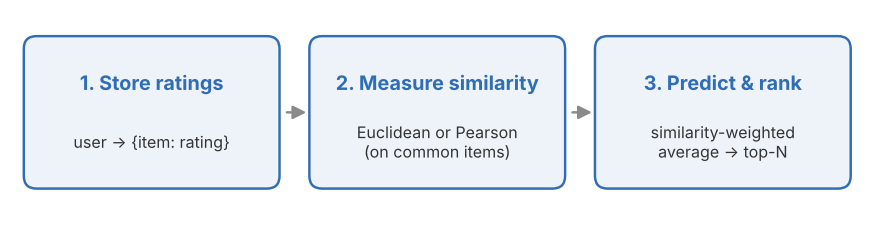

In [ ]:
#@title Figure: Pipeline
fig, ax = plt.subplots(figsize=(10, 2.4)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 2.4)
boxes = [("1. Store ratings", "user → {item: rating}"),
         ("2. Measure similarity", "Euclidean or Pearson\n(on common items)"),
         ("3. Predict & rank", "similarity-weighted\naverage → top-N")]
for k, (t, s) in enumerate(boxes):
    x = 0.2 + k * 3.35
    ax.add_patch(FancyBboxPatch((x, 0.35), 2.9, 1.7, boxstyle="round,pad=0.05,rounding_size=0.15",
                                fc="#eef3fa", ec=BLUE, lw=1.6))
    ax.text(x + 1.45, 1.55, t, ha="center", va="center", fontsize=13, weight="bold", color=BLUE)
    ax.text(x + 1.45, 0.85, s, ha="center", va="center", fontsize=10.5, color="#333")
    if k < 2:
        ax.add_patch(FancyArrowPatch((x + 3.0, 1.2), (x + 3.3, 1.2), arrowstyle="-|>", mutation_scale=18, color=GREY, lw=1.6))
plt.show()

## 3. Step 1: Data structure
A nested dictionary: `user → {item: rating}`.
If a user hasn't rated an item, it simply isn't in their dictionary (a missing value).

The tutorial uses famous computer scientists as users and CS topics as items. The cell below stores the tutorial's full dataset.

In [2]:
# Tutorial dataset: user -> {item: rating}, ratings on a 1-5 scale
data = {
    'Alan Perlis': {'Artificial intelligence': 1.46, 'Systems programming': 5.0,
                    'Software engineering': 3.34, 'Databases': 2.32},
    'Marvin Minsky': {'Artificial intelligence': 5.0, 'Systems programming': 2.54,
                      'Computation': 4.32, 'Algorithms': 2.76},
    'John McCarthy': {'Artificial intelligence': 5.0, 'Programming language theory': 4.72,
                      'Systems programming': 3.25, 'Concurrency': 3.61, 'Formal methods': 3.58,
                      'Computation': 3.23, 'Algorithms': 3.03},
    'Edsger Dijkstra': {'Programming language theory': 4.34, 'Systems programming': 4.52,
                        'Software engineering': 4.04, 'Concurrency': 3.97,
                        'Formal methods': 5.0, 'Algorithms': 4.92},
    'Donald Knuth': {'Programming language theory': 4.33, 'Systems programming': 3.57,
                     'Computation': 4.39, 'Algorithms': 5.0},
    'John Backus': {'Programming language theory': 4.58, 'Systems programming': 4.43,
                    'Software engineering': 4.38, 'Formal methods': 2.42, 'Databases': 2.80},
    'Robert Floyd': {'Programming language theory': 4.24, 'Systems programming': 2.17,
                     'Concurrency': 2.92, 'Formal methods': 5.0, 'Computation': 3.18,
                     'Algorithms': 5.0},
    'Tony Hoare': {'Programming language theory': 4.64, 'Systems programming': 4.38,
                   'Software engineering': 3.62, 'Concurrency': 4.88,
                   'Formal methods': 4.72, 'Algorithms': 4.38},
    'Edgar Codd': {'Systems programming': 4.60, 'Software engineering': 3.54,
                   'Concurrency': 4.28, 'Formal methods': 1.53, 'Databases': 5.0},
    'Dennis Ritchie': {'Programming language theory': 3.45, 'Systems programming': 5.0,
                       'Software engineering': 4.83},
    'Niklaus Wirth': {'Programming language theory': 4.23, 'Systems programming': 4.22,
                      'Software engineering': 4.74, 'Formal methods': 3.83, 'Algorithms': 3.95},
    'Robin Milner': {'Programming language theory': 5.0, 'Systems programming': 1.66,
                     'Concurrency': 4.62, 'Formal methods': 3.94},
    'Leslie Lamport': {'Programming language theory': 1.5, 'Systems programming': 2.76,
                       'Software engineering': 3.76, 'Concurrency': 5.0,
                       'Formal methods': 4.93, 'Algorithms': 4.63},
    'Michael Stonebraker': {'Systems programming': 4.67, 'Software engineering': 3.86,
                            'Concurrency': 4.14, 'Databases': 5.0},
}

# Quick look: how sparse is the data?
items = sorted({item for ratings in data.values() for item in ratings})
n_ratings = sum(len(r) for r in data.values())
print(f"{len(data)} users, {len(items)} items, {n_ratings} ratings")
print(f"Filled cells: {n_ratings / (len(data) * len(items)):.0%} of the user-item matrix")

14 users, 9 items, 69 ratings
Filled cells: 55% of the user-item matrix


The same data as a matrix. Many cells are empty, which is normal for real recommender data (it is *sparse*). The goal is to fill in the grey cells:

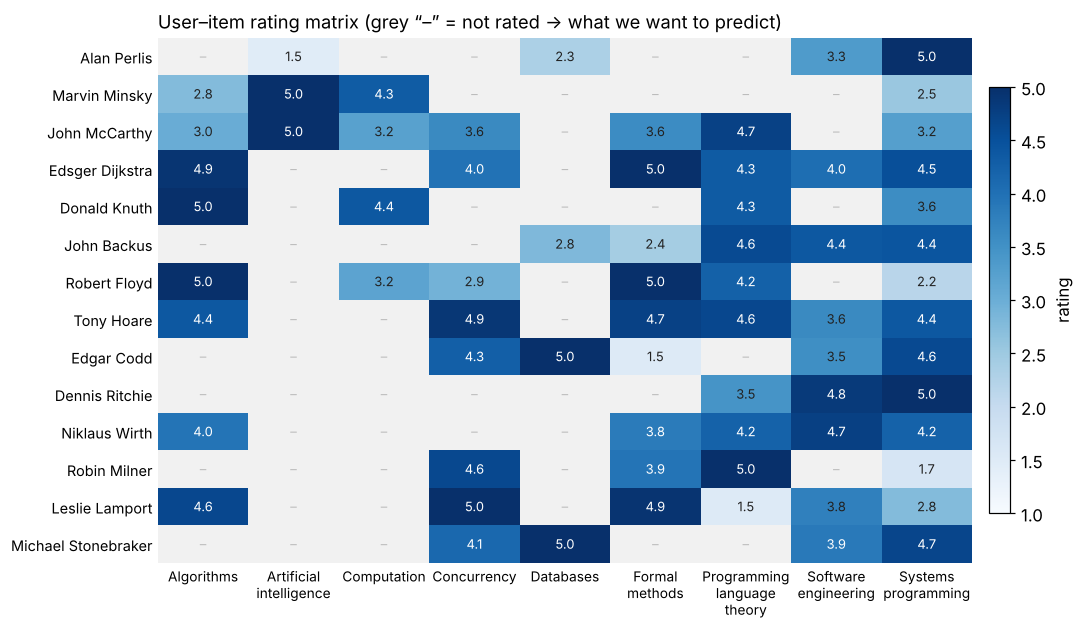

In [ ]:
#@title Figure: User-item matrix
users = list(data)
items = sorted({i for u in data.values() for i in u})
M = np.full((len(users), len(items)), np.nan)
for r, u in enumerate(users):
    for c, it in enumerate(items):
        if it in data[u]: M[r, c] = data[u][it]
fig, ax = plt.subplots(figsize=(10, 6.2))
cmap = plt.get_cmap("Blues").copy(); cmap.set_bad("#f1f1f1")
im = ax.imshow(M, cmap=cmap, vmin=1, vmax=5, aspect="auto")
for r in range(len(users)):
    for c in range(len(items)):
        v = M[r, c]
        ax.text(c, r, "–" if np.isnan(v) else f"{v:.1f}", ha="center", va="center", fontsize=8.5,
                color=("#bbb" if np.isnan(v) else ("white" if v > 3.8 else "#222")))
ax.set_xticks(range(len(items)), [i.replace(" ", "\n") for i in items], fontsize=9)
ax.set_yticks(range(len(users)), users, fontsize=9.5)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="rating")
ax.set_title("User–item rating matrix (grey “–” = not rated → what we want to predict)", fontsize=12, loc="left")
plt.show()

## 4. Step 2: Similarity between two users
Similarity is always computed **only on the items both users have rated**.

### 4a. Euclidean distance score
**Idea:** treat each user's ratings as a point; users whose points are close have similar taste.

- Distance: $d = \sqrt{\sum (r_A - r_B)^2}$ over common items
- Turn distance into similarity (between 0 and 1, avoids divide-by-zero):

  $$sim = \frac{1}{1 + d}$$
  1 means identical taste, near 0 means very different.

**Example (tutorial data):** with only two items as axes, each user is a point. McCarthy and Hoare are close (similar taste), while Ritchie and Lamport are far apart:

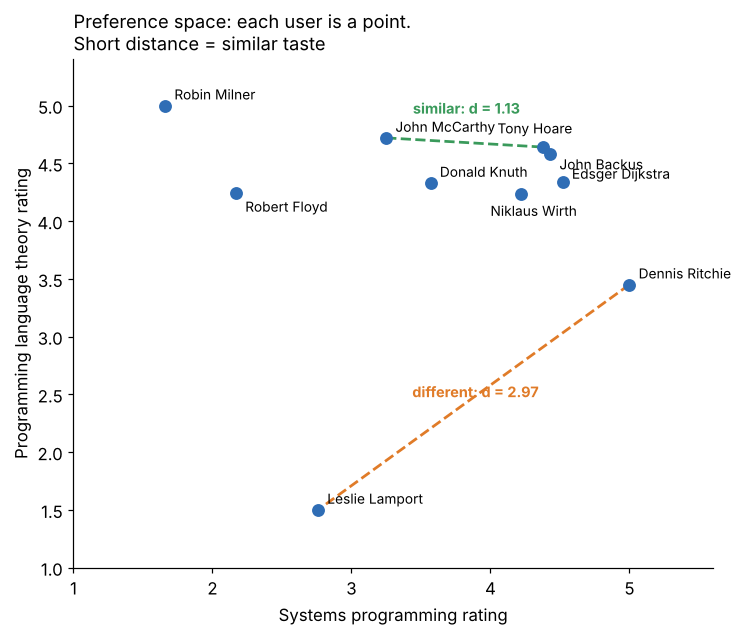

In [ ]:
#@title Figure: Preference space
A, B = "Systems programming", "Programming language theory"
pts = [(u, data[u][A], data[u][B]) for u in data if A in data[u] and B in data[u]]
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter([p[1] for p in pts], [p[2] for p in pts], s=55, color=BLUE, zorder=3)
offsets = {"Robert Floyd": (6, -12), "Tony Hoare": (-30, 9), "John Backus": (6, -10), "Niklaus Wirth": (-20, -14), "Edsger Dijkstra": (6, 2)}
for u, x, y in pts:
    ax.annotate(u, (x, y), xytext=offsets.get(u, (6, 4)), textcoords="offset points", fontsize=9)
# show the distance between two similar users and two different users
def seg(u1, u2, col, label):
    x1, y1 = data[u1][A], data[u1][B]; x2, y2 = data[u2][A], data[u2][B]
    ax.plot([x1, x2], [y1, y2], "--", color=col, lw=1.8, zorder=2)
    d = sqrt((x1-x2)**2 + (y1-y2)**2)
    ax.text((x1+x2)/2, (y1+y2)/2 + (0.25 if label == "similar" else 0), f" {label}: d = {d:.2f}", color=col, fontsize=9.5, weight="bold", ha="center")
seg("John McCarthy", "Tony Hoare", GREEN, "similar")
seg("Dennis Ritchie", "Leslie Lamport", ORANGE, "different")
ax.set_xlabel(A + " rating"); ax.set_ylabel(B + " rating")
ax.set_xlim(1, 5.6); ax.set_ylim(1, 5.4)
ax.set_title("Preference space: each user is a point.\nShort distance = similar taste", loc="left", fontsize=12)
plt.show()

In [3]:
from math import sqrt

def euclidean_similarity(data, a, b):
    """Similarity in (0, 1] based on Euclidean distance over common items."""
    # items rated by both users
    common = [item for item in data[a] if item in data[b]]
    if not common:
        return 0  # no overlap -> no evidence of similarity
    # Euclidean distance over common items
    d = sqrt(sum((data[a][i] - data[b][i]) ** 2 for i in common))
    # convert distance to similarity: d = 0 -> 1, large d -> close to 0
    return 1 / (1 + d)

# The two pairs from the chart above (but now using ALL their common items)
print("McCarthy vs Hoare   :", round(euclidean_similarity(data, 'John McCarthy', 'Tony Hoare'), 3))
print("Ritchie  vs Lamport :", round(euclidean_similarity(data, 'Dennis Ritchie', 'Leslie Lamport'), 3))

McCarthy vs Hoare   : 0.29
Ritchie  vs Lamport : 0.241


**Weakness:** it is sensitive to *rating scale*. If one user always rates 1 point lower than another (a "harsh" rater) but agrees on the *order* of preferences, Euclidean still says they are different.

### 4b. Pearson correlation coefficient (PCC)
**Idea:** instead of "are the ratings close?", ask "do the ratings go up and down together?"
- Range: **+1** (perfect agreement), **0** (no linear relation), **−1** (opposite taste)
- Plot user A's ratings vs user B's ratings for common items: the slope of the best-fit line shows the correlation.

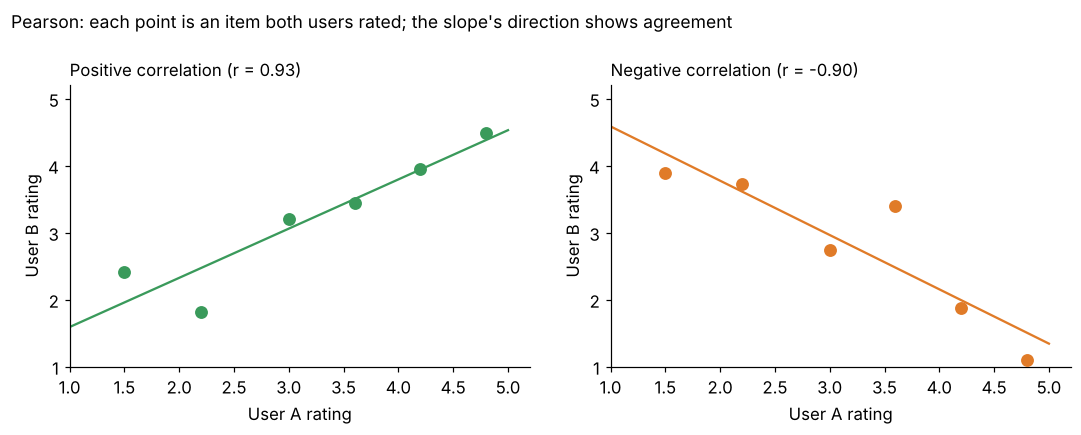

In [ ]:
#@title Figure: Pearson: positive vs negative correlation
rng = np.random.default_rng(3)
xa = np.array([1.5, 2.2, 3.0, 3.6, 4.2, 4.8])
pos = np.clip(xa * 0.8 + 0.7 + rng.normal(0, 0.25, 6), 1, 5)
neg = np.clip(6 - xa + rng.normal(0, 0.3, 6), 1, 5)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, y, col, name in [(axs[0], pos, GREEN, "positive"), (axs[1], neg, ORANGE, "negative")]:
    r = np.corrcoef(xa, y)[0, 1]
    ax.scatter(xa, y, s=55, color=col, zorder=3)
    m, c = np.polyfit(xa, y, 1); ax.plot([1, 5], [m+c, 5*m+c], color=col)
    ax.set_xlim(1, 5.2); ax.set_ylim(1, 5.2)
    ax.set_xlabel("User A rating"); ax.set_ylabel("User B rating")
    ax.set_title(f"{name.capitalize()} correlation (r = {r:.2f})", loc="left", fontsize=11)
fig.suptitle("Pearson: each point is an item both users rated; the slope's direction shows agreement",
             x=0.02, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

- **Advantage:** it removes the harshness/generosity effect, because it looks at each user's ratings relative to their own average.

Formula used in the code (the "computational form" of Pearson's *r*, with $n$ common items):

$$r = \frac{\sum xy - \frac{\sum x \sum y}{n}}{\sqrt{\left(\sum x^2 - \frac{(\sum x)^2}{n}\right)\left(\sum y^2 - \frac{(\sum y)^2}{n}\right)}}$$

In [4]:
def pearson_similarity(data, a, b):
    """Pearson correlation (-1..1) between two users over their common items."""
    common = [item for item in data[a] if item in data[b]]
    n = len(common)
    if n == 0:
        return 0
    x = [data[a][i] for i in common]  # user A's ratings
    y = [data[b][i] for i in common]  # user B's ratings

    # computational form of Pearson's r
    sum_x, sum_y = sum(x), sum(y)
    sum_x2 = sum(v ** 2 for v in x)
    sum_y2 = sum(v ** 2 for v in y)
    sum_xy = sum(xi * yi for xi, yi in zip(x, y))

    numerator = sum_xy - (sum_x * sum_y / n)
    denominator = sqrt((sum_x2 - sum_x ** 2 / n) * (sum_y2 - sum_y ** 2 / n))
    if denominator == 0:
        return 0  # e.g. only 1 common item, or same rating for every common item
    return numerator / denominator

print("McCarthy vs Hoare   :", round(pearson_similarity(data, 'John McCarthy', 'Tony Hoare'), 3))
print("Ritchie  vs Lamport :", round(pearson_similarity(data, 'Dennis Ritchie', 'Leslie Lamport'), 3))

McCarthy vs Hoare   : 0.435
Ritchie  vs Lamport : 0.849


**What the two outputs above show:** the chart used only 2 items, where Ritchie and Lamport look very different. Over *all* their common items (3 items), the picture changes:
- Euclidean: McCarthy–Hoare (0.29) and Ritchie–Lamport (0.24) are now close, because more items add more distance.
- Pearson: Ritchie–Lamport is 0.85. Their ratings go up and down together, even though Lamport gives lower scores.

Lesson: similarity depends on **which items** you compare, and with very few common items the numbers are not reliable.

**Why this matters:** two users with the same taste, but one rates 1.5 points lower. Euclidean calls them different; Pearson correctly calls them identical:

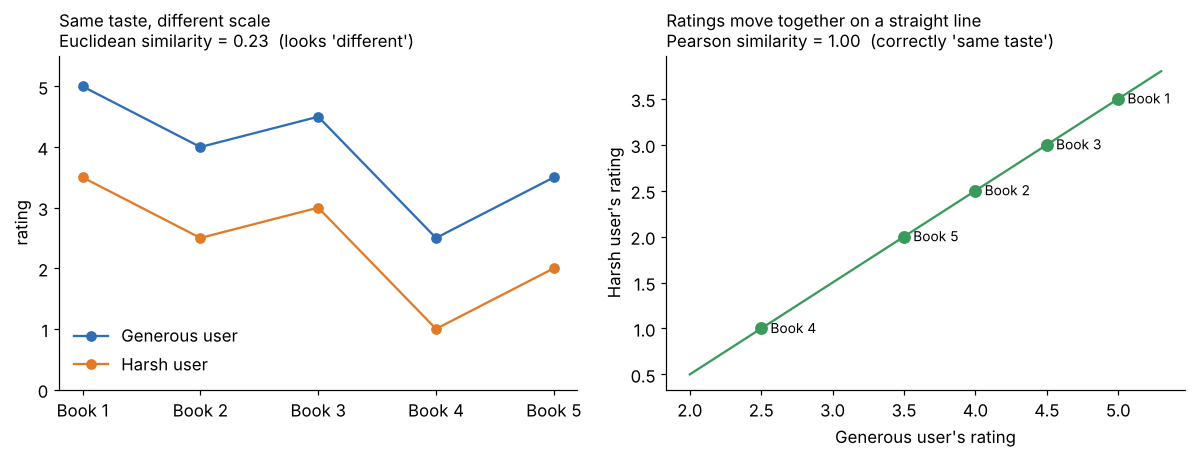

In [ ]:
#@title Figure: Euclidean vs Pearson: harsh rater
items4 = ["Book 1", "Book 2", "Book 3", "Book 4", "Book 5"]
generous = np.array([5.0, 4.0, 4.5, 2.5, 3.5])
harsh = generous - 1.5
d4 = {"G": dict(zip(items4, generous)), "H": dict(zip(items4, harsh))}
e, p = euclidean_similarity(d4, "G", "H"), pearson_similarity(d4, "G", "H")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))
x = np.arange(len(items4))
ax1.plot(x, generous, "o-", color=BLUE, label="Generous user"); ax1.plot(x, harsh, "o-", color=ORANGE, label="Harsh user")
ax1.set_xticks(x, items4); ax1.set_ylim(0, 5.5); ax1.set_ylabel("rating"); ax1.legend(frameon=False, loc="lower left")
ax1.set_title(f"Same taste, different scale\nEuclidean similarity = {e:.2f}  (looks 'different')", loc="left", fontsize=11)
ax2.scatter(generous, harsh, s=55, color=GREEN, zorder=3)
m, c = np.polyfit(generous, harsh, 1); xs = np.linspace(2, 5.3, 10)
ax2.plot(xs, m*xs + c, color=GREEN, lw=1.5)
for i, t in enumerate(items4): ax2.annotate(t, (generous[i], harsh[i]), xytext=(6, -3), textcoords="offset points", fontsize=9)
ax2.set_xlabel("Generous user's rating"); ax2.set_ylabel("Harsh user's rating")
ax2.set_title(f"Ratings move together on a straight line\nPearson similarity = {p:.2f}  (correctly 'same taste')", loc="left", fontsize=11)
fig.tight_layout(); plt.show()

The cell below reproduces exactly this example.

In [5]:
# Same taste, different scale: the harsh user = generous user - 1.5
books = ["Book 1", "Book 2", "Book 3", "Book 4", "Book 5"]
generous = [5.0, 4.0, 4.5, 2.5, 3.5]
toy = {
    "Generous": dict(zip(books, generous)),
    "Harsh":    {b: r - 1.5 for b, r in zip(books, generous)},
}
print("Euclidean:", round(euclidean_similarity(toy, "Generous", "Harsh"), 2))  # low -> 'different'
print("Pearson  :", round(pearson_similarity(toy, "Generous", "Harsh"), 2))    # 1.0 -> 'same taste'

Euclidean: 0.23
Pearson  : 1.0


## 5. Step 3: Predict ratings and recommend
**Idea:** to predict how user *u* would rate item *i*, take a **similarity-weighted average** of other users' ratings of *i*:

$$\text{predicted}(u, i) = \frac{\sum_v sim(u, v) \times rating(v, i)}{\sum_v sim(u, v)}$$

summed over users *v* who rated item *i*.
- Similar users count more.
- Dividing by the sum of similarities stops popular items (rated by many users) from getting an unfairly large score.

The tutorial passes the similarity function as an argument (a higher-order function), so you can easily compare Euclidean vs Pearson.

In [6]:
def recommend(data, person, bound, similarity=pearson_similarity):
    """Top-`bound` (predicted_rating, item) pairs for items `person` hasn't rated."""
    totals, sim_sums = {}, {}
    for other in data:
        if other == person:
            continue
        sim = similarity(data, person, other)
        if sim <= 0:
            continue  # ignore users with no / negative similarity
        for item, rating in data[other].items():
            if item not in data[person]:          # only unseen items
                totals[item] = totals.get(item, 0) + sim * rating
                sim_sums[item] = sim_sums.get(item, 0) + sim
    # weighted average = predicted rating
    predictions = [(round(totals[i] / sim_sums[i], 2), i) for i in totals]
    predictions.sort(reverse=True)               # best first
    return predictions[:bound]                   # top-N recommendations

## 6. Worked example from the tutorial
- **Question:** what should we recommend to *Alan Perlis* and *Marvin Minsky*?
- For Perlis, the system suggests *Algorithms* and *Concurrency* as top picks (same with both measures).
- For Minsky, the predicted scores for *Programming language theory* and *Formal methods* change a lot depending on whether Euclidean or Pearson is used. His closest users (Robin Milner and John McCarthy) are quite different from each other, and Milner rates more harshly. So the **choice of similarity measure and of `bound`** can change the recommendations a lot.

The cell below runs both measures for both users. (My numbers may differ slightly from the article's, since the exact formulas there may differ a little.)

In [7]:
for person in ['Alan Perlis', 'Marvin Minsky']:
    print(f"=== {person} ===")
    print("Euclidean:", recommend(data, person, 5, euclidean_similarity))
    print("Pearson  :", recommend(data, person, 5, pearson_similarity))
    print()

=== Alan Perlis ===
Euclidean: [(4.39, 'Algorithms'), (4.26, 'Concurrency'), (4.13, 'Programming language theory'), (4.0, 'Formal methods'), (3.86, 'Computation')]
Pearson  : [(4.65, 'Algorithms'), (4.43, 'Concurrency'), (4.24, 'Programming language theory'), (4.16, 'Formal methods')]

=== Marvin Minsky ===
Euclidean: [(4.21, 'Concurrency'), (4.16, 'Programming language theory'), (4.04, 'Software engineering'), (3.93, 'Databases'), (3.82, 'Formal methods')]
Pearson  : [(4.58, 'Formal methods'), (4.24, 'Concurrency'), (3.9, 'Software engineering'), (3.48, 'Programming language theory')]



The Minsky results from the cell above, as a chart:

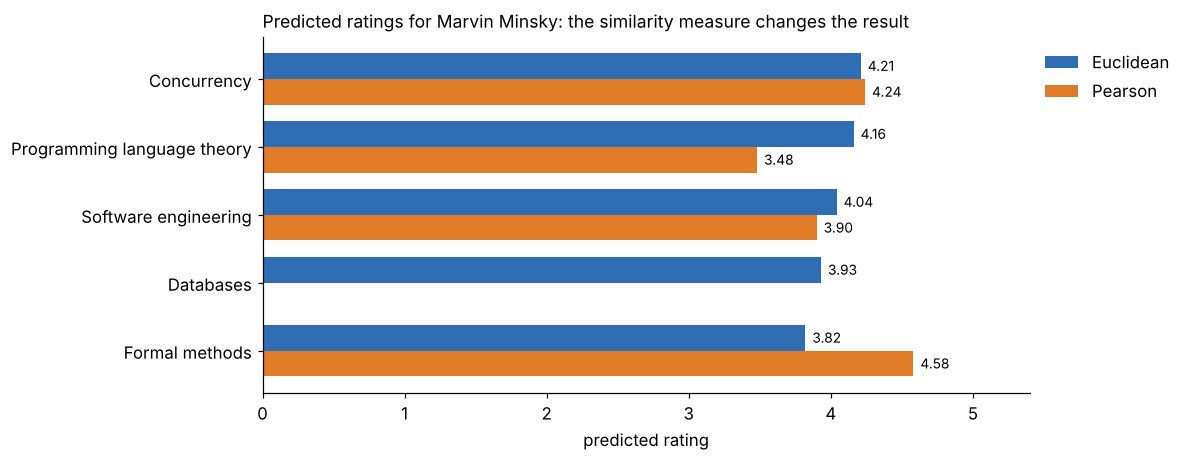

In [ ]:
#@title Figure: Recommendations for Marvin Minsky
re = dict((i, v) for v, i in recommend(data, "Marvin Minsky", 10, euclidean_similarity))
rp = dict((i, v) for v, i in recommend(data, "Marvin Minsky", 10, pearson_similarity))
its = sorted(set(re) | set(rp), key=lambda i: -re.get(i, 0))
fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(its)); h = 0.38
ax.barh(y - h/2, [re.get(i, 0) for i in its], h, color=BLUE, label="Euclidean")
ax.barh(y + h/2, [rp.get(i, 0) for i in its], h, color=ORANGE, label="Pearson")
for k, i in enumerate(its):
    if i in re: ax.text(re[i] + 0.05, k - h/2, f"{re[i]:.2f}", va="center", fontsize=9)
    if i in rp: ax.text(rp[i] + 0.05, k + h/2, f"{rp[i]:.2f}", va="center", fontsize=9)
ax.set_yticks(y, its); ax.invert_yaxis(); ax.set_xlim(0, 5.4); ax.set_xlabel("predicted rating")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Predicted ratings for Marvin Minsky: the similarity measure changes the result", loc="left", fontsize=11.5)
plt.show()

**How to read this chart:** each pair of bars is one item Minsky hasn't rated. Blue = prediction using Euclidean similarity, orange = using Pearson.
- *Formal methods* jumps from 3.82 (Euclidean) to 4.58 (Pearson), and *Programming language theory* drops from 4.16 to 3.48. The ranking changes.
- *Databases* has **no Pearson bar**: every user who rated Databases has zero or negative correlation with Minsky, so they are ignored and no prediction can be made. With Euclidean, everyone gets some positive similarity, so a prediction still appears.

The cell below checks that claim about Databases.

In [8]:
# Who rated Databases, and how similar are they to Minsky?
for user in data:
    if 'Databases' in data[user]:
        common = [i for i in data[user] if i in data['Marvin Minsky']]
        print(f"{user:20s} common items={len(common)}  "
              f"pearson={pearson_similarity(data, 'Marvin Minsky', user):+.2f}  "
              f"euclid={euclidean_similarity(data, 'Marvin Minsky', user):.2f}")

Alan Perlis          common items=2  pearson=-1.00  euclid=0.19
John Backus          common items=1  pearson=+0.00  euclid=0.35
Edgar Codd           common items=1  pearson=+0.00  euclid=0.33
Michael Stonebraker  common items=1  pearson=+0.00  euclid=0.32


## 7. Key takeaways
- Collaborative filtering = "people like you also liked...", using **ratings only**.
- **Euclidean** = closeness of ratings; simple but affected by rating scale.
- **Pearson** = agreement in rating *patterns*; handles harsh vs generous raters.
- Prediction = **similarity-weighted average** of neighbours' ratings.
- Results depend on the similarity measure, the data, and parameters like `bound`. Always compare.

## 8. Limitations to remember
- Similarity on only a few common items is unreliable (e.g. 1–2 shared items; see the Databases check above).
- **Cold start:** new users or new items with no ratings can't be handled.
- Comparing every user with every other user doesn't scale to large datasets.
- Item content (text, attributes) is ignored. Content-based or hybrid methods address this.

## 9. Try it

In [9]:
# 1) Who is most similar to Marvin Minsky? Rank all users with both measures
for name, fn in [("Euclidean", euclidean_similarity), ("Pearson", pearson_similarity)]:
    ranked = sorted(((round(fn(data, 'Marvin Minsky', u), 2), u) for u in data if u != 'Marvin Minsky'),
                    reverse=True)
    print(name, ranked[:3])

Euclidean [(0.53, 'Robin Milner'), (0.43, 'John McCarthy'), (0.35, 'Leslie Lamport')]
Pearson [(1.0, 'Leslie Lamport'), (1.0, 'Edsger Dijkstra'), (0.77, 'John McCarthy')]


**Look at the Pearson output above:** Lamport and Dijkstra both get a "perfect" 1.0 with Minsky. That is because they share only **2** items with him, and any 2 points always lie exactly on a straight line. This is a known weakness of Pearson with small overlaps. Real systems often require a minimum number of common items, or shrink the similarity when the overlap is small.

In [10]:
# 2) Add yourself as a new user and get recommendations
data['Me'] = {'Artificial intelligence': 5.0, 'Algorithms': 4.0, 'Databases': 2.0}
print(recommend(data, 'Me', 3, pearson_similarity))
del data['Me']  # remove again so other cells are unaffected

[(4.72, 'Programming language theory'), (3.77, 'Computation'), (3.61, 'Concurrency')]


In [11]:
# 3) Change `bound` and see how the list changes
print(recommend(data, 'Marvin Minsky', 2, euclidean_similarity))
print(recommend(data, 'Marvin Minsky', 10, euclidean_similarity))

[(4.21, 'Concurrency'), (4.16, 'Programming language theory')]
[(4.21, 'Concurrency'), (4.16, 'Programming language theory'), (4.04, 'Software engineering'), (3.93, 'Databases'), (3.82, 'Formal methods')]


## 10. My notes / questions
- ...